In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt
splits = {'train': 'Data/train-00000-of-00001.parquet', 'test': 'Data/test-00000-of-00001.parquet'}
df_train = pd.read_parquet(splits["train"])
df_test = pd.read_parquet( splits["test"])

Ytrain= df_train.label
Ytest= df_test.label
text_train = df_train.text
text_test= df_test.text
def clean(text):
    nonwords=["<br />"]
    for remove in nonwords:
        text = text.replace(remove, " ")
    text= text.lower()
    text = re.sub(r'[^A-Za-z\s]', ' ', text)
    return text

cleanedTrain= []
for text in text_train:
    cleanedTrain.append(clean(text).split())
cleanedTest= []
for text in text_test:
    cleanedTest.append(clean(text).split())

print(cleanedTrain[0])
n= len(cleanedTrain)

['i', 'rented', 'i', 'am', 'curious', 'yellow', 'from', 'my', 'video', 'store', 'because', 'of', 'all', 'the', 'controversy', 'that', 'surrounded', 'it', 'when', 'it', 'was', 'first', 'released', 'in', 'i', 'also', 'heard', 'that', 'at', 'first', 'it', 'was', 'seized', 'by', 'u', 's', 'customs', 'if', 'it', 'ever', 'tried', 'to', 'enter', 'this', 'country', 'therefore', 'being', 'a', 'fan', 'of', 'films', 'considered', 'controversial', 'i', 'really', 'had', 'to', 'see', 'this', 'for', 'myself', 'the', 'plot', 'is', 'centered', 'around', 'a', 'young', 'swedish', 'drama', 'student', 'named', 'lena', 'who', 'wants', 'to', 'learn', 'everything', 'she', 'can', 'about', 'life', 'in', 'particular', 'she', 'wants', 'to', 'focus', 'her', 'attentions', 'to', 'making', 'some', 'sort', 'of', 'documentary', 'on', 'what', 'the', 'average', 'swede', 'thought', 'about', 'certain', 'political', 'issues', 'such', 'as', 'the', 'vietnam', 'war', 'and', 'race', 'issues', 'in', 'the', 'united', 'states', 'i

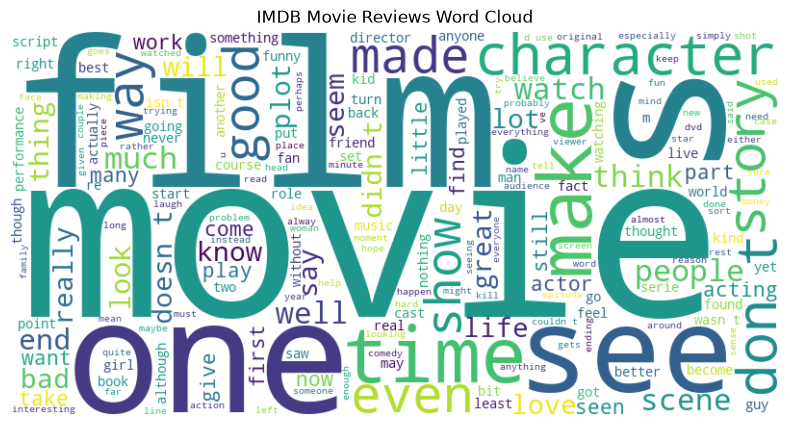

In [2]:
from wordcloud import WordCloud
entiretext=""
for text in text_train:
    entiretext += " "+clean(text)
for text in text_test:
    entiretext += " "+clean(text)
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(entiretext)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  
plt.title("IMDB Movie Reviews Word Cloud")
plt.show()

##  Tokenization

In [7]:
from sklearn.preprocessing import OneHotEncoder
import numpy as np
tokens={}
occurences=[]
for word in entiretext.split():
    if word in tokens:
        occurences[tokens[word]]+=1
    else:
        tokens[word]=len(occurences)
        occurences.append(1)


reducedtoken={}
minoccurence=10
for word in tokens:
    i = tokens[word]
    if occurences[i]>minoccurence:
        reducedtoken[word]= len(reducedtoken)
        
tokenamount=len(reducedtoken)


print("Out of ", len(tokens), "words only ",tokenamount, "occur more than ", minoccurence, "times in the entire test set.")

onehotTrain = np.zeros([n, tokenamount])
for i in range(n):
    for word in cleanedTrain[i]:
         if word in reducedtoken:# if the word is not known in the training set it will be ignored
            onehotTrain[i,reducedtoken[word]] +=1


onehotTest = np.zeros([n, tokenamount])
for i in range(n):
    for word in cleanedTest[i]:
        if word in reducedtoken:# if the word is not known in the training set it will be ignored
            onehotTest[i,reducedtoken[word]] +=1


Out of  99426 words only  26607 occur more than  10 times in the entire test set.


In [ ]:
from sklearn.linear_model import LogisticRegression


def calculate_and_print_accuracy(model, x, y_true, label):
    y_pred = model.predict(x)
    n_right_predictions = (y_pred == y_true).sum()
    print(f"{label} Accuracy: {100 * n_right_predictions / len(y_true):.2f}%")

lda_classifier = LogisticRegression(max_iter=1000)
lda_classifier.fit(onehotTrain, Ytrain)

calculate_and_print_accuracy(lda_classifier, onehotTest, Ytest, "LDA")